# Forward sensitivity and identifiability

**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.

## Data

Measured QC-only record plus a separate seeded synthetic calibration artifact; never merge these evidence classes.

## Method

The repository’s layered-earth operator uses the half-space response `Z=√(iωμ₀ρ)` and recursively propagates it through finite layers using `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)`, and `t=tanh(kh)`. The basal layer is infinite; geometry is 1D, isotropic and quasi-static. Call the existing `electromagnetics.impedance` and `curves` functions; do not reimplement them. Compare the exact synthetic truth with a stored fitted realization over the committed frequencies, plotting apparent resistivity (Ω·m) and phase (degrees) against period (s). Similar curves do not prove unique resistivity or thickness: dimensionality, static shift, correlated errors and fixed thickness are outside this calibration.

Parameters are log-resistivities: positive by construction, with equal steps representing equal multiplicative changes. Complex residuals use per-real-component sigma; real and imaginary parts both inform the fit. Frequencies are not independent depth samples: sensitivity kernels overlap, so one period does not identify one interface. Local sensitivity and coverage remain conditional on the fixed parameterization and cannot rule out global equivalence.

## State of the art

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib', 'scipy']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Call the repository layered-earth forward operator on its synthetic calibration target.
import json,sys
from pathlib import Path
sys.path.insert(0,str(root/"data-pipeline")); from electromagnetics import impedance,curves
cal=json.loads((root/"data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8")); f=cal["frequencies_hz"]; rho=cal["calibration_model"]; h=cal["fixed_thickness_m"]; z=impedance(rho,h,f); truth=curves(z,f)
print("synthetic rho Ω·m",rho,"fixed thickness m",h,"n frequencies",len(f))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
synthetic rho Ω·m [180.0, 20.0] fixed thickness m [450.0] n frequencies 24


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

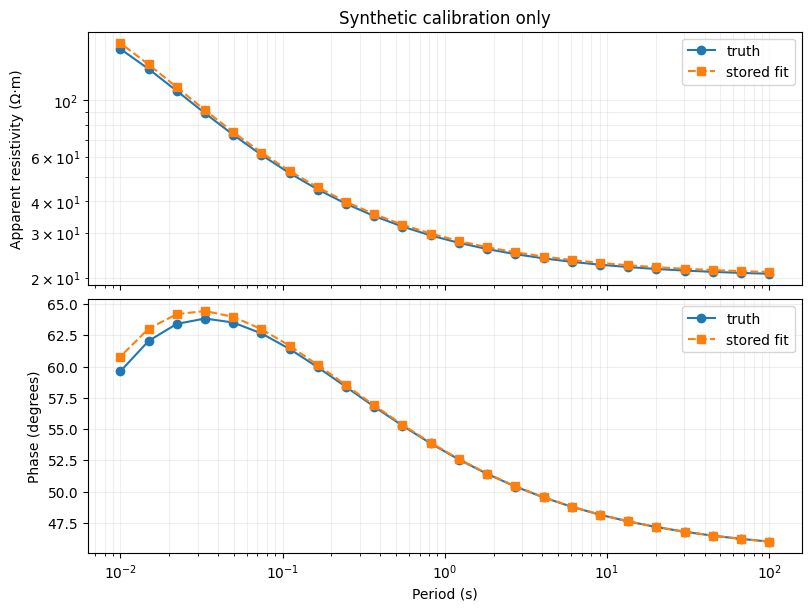

stored fitted rho Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Forward-project a stored fitted model and compare physical response curves.
import matplotlib.pyplot as plt
fit=cal["rows"][0]["model"]; other=curves(impedance(fit,h,f),f); T=1/np.asarray(f)
fig,ax=plt.subplots(2,1,figsize=(8,6),sharex=True,constrained_layout=True); ax[0].loglog(T,truth["apparent"],"o-",label="truth"); ax[0].loglog(T,other["apparent"],"s--",label="stored fit"); ax[1].semilogx(T,truth["phase"],"o-",label="truth"); ax[1].semilogx(T,other["phase"],"s--",label="stored fit")
ax[0].set_ylabel("Apparent resistivity (Ω·m)"); ax[1].set_ylabel("Phase (degrees)"); ax[1].set_xlabel("Period (s)"); [a.grid(True,which="both",alpha=.2) or a.legend() for a in ax]; ax[0].set_title("Synthetic calibration only"); plt.show(); print("stored fitted rho Ω·m",fit)

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)